In [20]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid

import seaborn as sn  # for heatmaps
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

In [21]:
transform = transforms.ToTensor()

In [22]:
train_data = datasets.CIFAR10(
    root="./Data/", train=True, download=True, transform=transform
)
test_data = datasets.CIFAR10(
    root="./Data/", train=False, download=True, transform=transform
)

Files already downloaded and verified
Files already downloaded and verified


In [23]:
train_data

Dataset CIFAR10
    Number of datapoints: 50000
    Root location: ./Data/
    Split: Train
    StandardTransform
Transform: ToTensor()

In [24]:
test_data

Dataset CIFAR10
    Number of datapoints: 10000
    Root location: ./Data/
    Split: Test
    StandardTransform
Transform: ToTensor()

In [25]:
torch.manual_seed(101)
train_loader = DataLoader(train_data, batch_size=10, shuffle=True)
test_loader = DataLoader(test_data, batch_size=10, shuffle=False)

In [26]:
class_names = [
    "plane",
    "car",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck",
]
len(class_names)

10

In [27]:
for images, labels in train_loader:
    break

In [28]:
images.shape

torch.Size([10, 3, 32, 32])

In [29]:
labels.shape

torch.Size([10])

In [30]:
np.array(class_names)[labels]

array(['car', 'dog', 'ship', 'car', 'frog', 'car', 'frog', 'cat', 'horse',
       'truck'], dtype='<U5')

label:  [1 5 8 1 6 1 6 3 7 9]
Class:  car dog ship car frog car frog cat horse truck
Class:  car dog ship car frog car frog cat horse truck
Class:  car dog ship car frog car frog cat horse truck


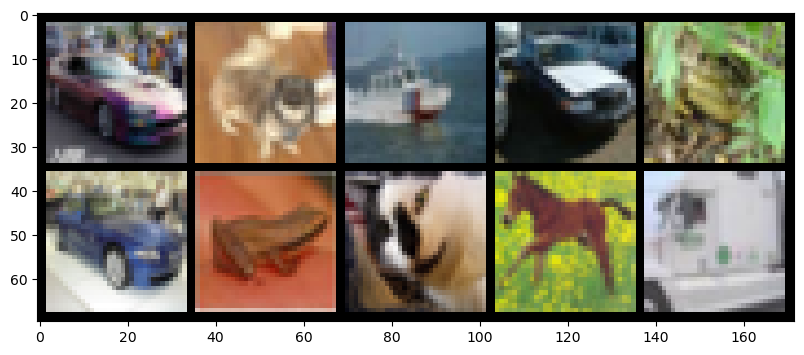

In [31]:
# np.printoptions(formatter=dict(int=lambda x: f'{x:4}'))
print("label: ", labels.numpy())
print("Class: ", *np.array([class_names[i] for i in labels]))
print("Class: ", *[class_names[i] for i in labels])
print("Class: ", *np.array(class_names)[labels])


im = make_grid(images, nrow=5)
plt.figure(figsize=(10, 4))
plt.imshow(im.permute(1, 2, 0))

In [32]:
class ConvolutionaNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 6, 5)
        self.conv2 = nn.Conv2d(6, 16, 3)
        # self.fc1 = nn.Linear(9*9*16, 120)
        self.fc1 = nn.Linear(6 * 6 * 16, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, X):
        X = F.relu(self.conv1(X))
        X = F.max_pool2d(X, 2, 2)
        X = F.relu(self.conv2(X))
        X = F.max_pool2d(X, 2, 2)
        X = X.view(len(X), -1)
        X = F.relu(self.fc1(X))
        X = F.relu(self.fc2(X))
        X = self.fc3(X)

        return X

In [33]:
# class ConvolutionaNetwork(nn.Module):
#     def __init__(self):
#         super().__init__()
#         self.conv1 = nn.Conv2d(3, 6, 5)
#         self.conv2 = nn.Conv2d(6, 16, 3)
#         self.conv3 = nn.Conv2d(16, 26, 3)
#         # self.fc1 = nn.Linear(9*9*16, 120)
#         self.fc1 = nn.LazyLinear(120)
#         self.fc2 = nn.Linear(120, 84)
#         self.fc3 = nn.Linear(84, 10)

#     def forward(self, X):
#         X = F.relu(self.conv1(X))
#         X = F.max_pool2d(X, 2, 2)
#         X = F.relu(self.conv2(X))
#         X = F.max_pool2d(X, 2, 2)
#         X = F.relu(self.conv3(X))
#         X = F.max_pool2d(X, 2, 2)
#         X = X.view(len(X), -1)
#         X = F.relu(self.fc1(X))
#         X = F.relu(self.fc2(X))
#         X = self.fc3(X)

#         return X

In [34]:
torch.manual_seed(101)
model = ConvolutionaNetwork()
model

ConvolutionaNetwork(
  (conv1): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1))
  (conv2): Conv2d(6, 16, kernel_size=(3, 3), stride=(1, 1))
  (fc1): Linear(in_features=576, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)

In [35]:
# total = 0
# for name, param in model.named_parameters():
#     print(name, param.shape)
#     total += param.numel()

# print(total)

In [36]:
criterion = nn.CrossEntropyLoss()
optimizers = torch.optim.Adam(model.parameters(), lr=0.001)

In [37]:
import time

start_time = time.time()

# variables
epochs = 10
train_losses = []
test_losses = []
train_correct = []
test_correct = []

# For loop epochs
for i in range(epochs):
    trn_corr = 0
    tst_corr = 0

    # train
    for b, (X_train, y_train) in enumerate(train_loader):
        b += 1

        y_pred = model(X_train)  # no flatten
        loss = criterion(y_pred, y_train)
        predicted = torch.max(y_pred.data, 1)[1]
        trn_corr += (predicted == y_train).sum()

        optimizers.zero_grad()
        loss.backward()
        optimizers.step()

        if b % 1000 == 0:
            acc = trn_corr * 100 / len(X_train) / b
            print(
                f"Epoch: {i + 1:2} Batch: {b:4} [{len(X_train) * b}/{len(train_data)}] loss: {loss.item():2.8f} accuracy: {acc:2.2f}%"
            )

    train_losses.append(loss.item())
    train_correct.append(trn_corr)

    # validation
    with torch.no_grad():
        for b, (X_test, y_test) in enumerate(test_loader):
            y_val = model(X_test)
            predicted = torch.max(y_val.data, 1)[1]
            tst_corr += (predicted == y_test).sum()

    loss = criterion(y_val, y_test)
    test_losses.append(loss.item())
    test_correct.append(tst_corr)

during = time.time() - start_time
mins = during // 60
secs = during - mins * 60
print(f"Traning took {mins:2.0f}:{secs:2.0f}")

Epoch:  1 Batch: 1000 [10000/50000] loss: 2.11340332 accuracy: 26.35%
Epoch:  1 Batch: 2000 [20000/50000] loss: 1.87134516 accuracy: 32.28%
Epoch:  1 Batch: 3000 [30000/50000] loss: 0.97591323 accuracy: 35.76%
Epoch:  1 Batch: 4000 [40000/50000] loss: 1.13286090 accuracy: 37.88%
Epoch:  1 Batch: 5000 [50000/50000] loss: 1.46742785 accuracy: 39.71%
Epoch:  2 Batch: 1000 [10000/50000] loss: 1.40047622 accuracy: 48.99%
Epoch:  2 Batch: 2000 [20000/50000] loss: 1.15713143 accuracy: 49.25%
Epoch:  2 Batch: 3000 [30000/50000] loss: 1.39166188 accuracy: 50.04%
Epoch:  2 Batch: 4000 [40000/50000] loss: 0.99590862 accuracy: 50.42%
Epoch:  2 Batch: 5000 [50000/50000] loss: 1.80332410 accuracy: 50.85%
Epoch:  3 Batch: 1000 [10000/50000] loss: 1.66626620 accuracy: 54.70%
Epoch:  3 Batch: 2000 [20000/50000] loss: 1.40814281 accuracy: 54.43%
Epoch:  3 Batch: 3000 [30000/50000] loss: 1.58125854 accuracy: 55.03%
Epoch:  3 Batch: 4000 [40000/50000] loss: 1.57492685 accuracy: 55.12%
Epoch:  3 Batch: 500

In [38]:
torch.save(model, "./models/myCIFARmodel.pt")
torch.save(model.state_dict(), "./models/myCIFARmodel_wb.pt")

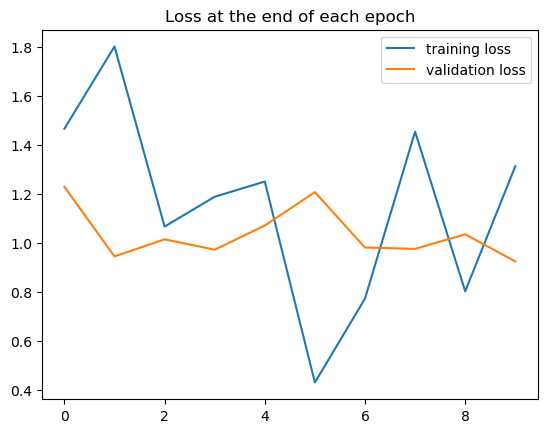

In [39]:
plt.plot(train_losses, label="training loss")
plt.plot(test_losses, label="validation loss")
plt.title("Loss at the end of each epoch")
plt.legend()


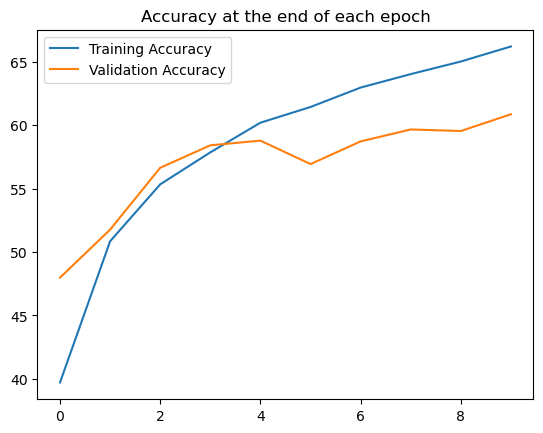

In [40]:
train_acc = np.array(train_correct) * 100 / len(train_data)
test_acc = np.array(test_correct) * 100 / len(test_data)
plt.plot(train_acc, label="Training Accuracy")
plt.plot(test_acc, label="Validation Accuracy")
plt.title("Accuracy at the end of each epoch")
plt.legend();

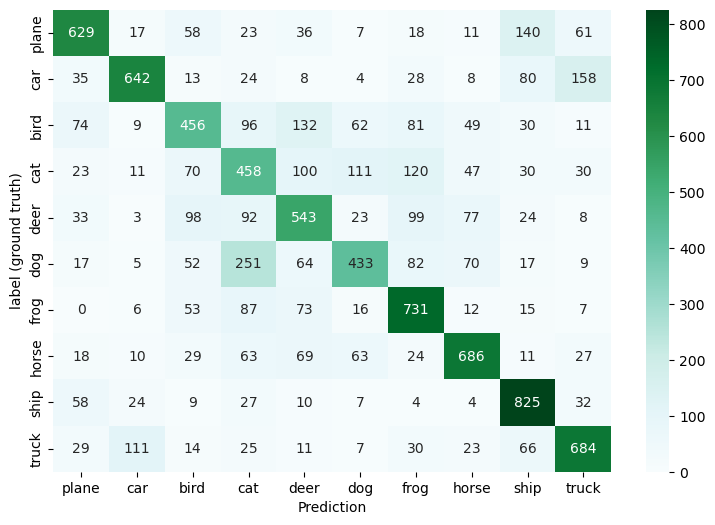

In [41]:
test_load_all = DataLoader(test_data, batch_size=len(test_data), shuffle=False)

correct = 0

with torch.no_grad():
    for X_test, y_test in test_load_all:
        y_val = model(X_test)
        predicted = torch.max(y_val.data, 1)[1]
        correct += (predicted == y_test).sum()
arr = confusion_matrix(y_test, predicted)
df_cm = pd.DataFrame(arr, class_names, class_names)
plt.figure(figsize=(9, 6))
sn.heatmap(df_cm, annot=True, fmt="d", cmap="BuGn")
plt.xlabel("Prediction")
plt.ylabel("label (ground truth)")
plt.show();

In [42]:
confusion_matrix(y_test, predicted)

array([[629,  17,  58,  23,  36,   7,  18,  11, 140,  61],
       [ 35, 642,  13,  24,   8,   4,  28,   8,  80, 158],
       [ 74,   9, 456,  96, 132,  62,  81,  49,  30,  11],
       [ 23,  11,  70, 458, 100, 111, 120,  47,  30,  30],
       [ 33,   3,  98,  92, 543,  23,  99,  77,  24,   8],
       [ 17,   5,  52, 251,  64, 433,  82,  70,  17,   9],
       [  0,   6,  53,  87,  73,  16, 731,  12,  15,   7],
       [ 18,  10,  29,  63,  69,  63,  24, 686,  11,  27],
       [ 58,  24,   9,  27,  10,   7,   4,   4, 825,  32],
       [ 29, 111,  14,  25,  11,   7,  30,  23,  66, 684]], dtype=int64)